In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("Libraries imported successfully!")

data_path = Path("data/AmesHousing.csv")

if not data_path.exists():
    data_path = Path("../data/AmesHousing.csv")

housing = pd.read_csv(data_path, sep="\t")

print("Dataset shape:", housing.shape)
print(housing.head())


Libraries imported successfully!
Dataset shape: (2930, 82)
   Order        PID  MS SubClass MS Zoning  Lot Frontage  Lot Area Street  \
0      1  526301100           20        RL         141.0     31770   Pave   
1      2  526350040           20        RH          80.0     11622   Pave   
2      3  526351010           20        RL          81.0     14267   Pave   
3      4  526353030           20        RL          93.0     11160   Pave   
4      5  527105010           60        RL          74.0     13830   Pave   

  Alley Lot Shape Land Contour  ... Pool Area Pool QC  Fence Misc Feature  \
0   NaN       IR1          Lvl  ...         0     NaN    NaN          NaN   
1   NaN       Reg          Lvl  ...         0     NaN  MnPrv          NaN   
2   NaN       IR1          Lvl  ...         0     NaN    NaN         Gar2   
3   NaN       Reg          Lvl  ...         0     NaN    NaN          NaN   
4   NaN       IR1          Lvl  ...         0     NaN  MnPrv          NaN   

  Misc Val Mo S

In [2]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Separate features from identifiers and sale price
X = housing.drop(
    columns=["Order", "PID", "SalePrice"],
    errors="ignore"
)

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

# Preprocessing pipelines
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Transform the dataset
X_processed = preprocessor.fit_transform(X)

print("Original shape:", X.shape)
print("Processed shape:", X_processed.shape)
print("Missing values:", np.isnan(X_processed).sum())


Numeric features: 36
Categorical features: 43
Original shape: (2930, 79)
Processed shape: (2930, 319)
Missing values: 0


/var/folders/fj/1pcy35m558gc_b3s7b48vwk40000gn/T/ipykernel_70134/2643558031.py:17: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [3]:

from sklearn.decomposition import PCA

# Variance thresholds
variance_thresholds = [0.98, 0.95, 0.90, 0.80]

# Store PCA models and transformed datasets
pca_models = {}
pca_datasets = {}

for threshold in variance_thresholds:

    pca = PCA(n_components=threshold)

    X_pca = pca.fit_transform(X_processed)

    pca_models[threshold] = pca
    pca_datasets[threshold] = X_pca

    print(f"\nPCA - {int(threshold * 100)}% variance")
    print("Number of components:", pca.n_components_)
    print("Transformed shape:", X_pca.shape)
    print(
        "Explained variance:",
        round(sum(pca.explained_variance_ratio_), 4)
    )



PCA - 98% variance
Number of components: 142
Transformed shape: (2930, 142)
Explained variance: 0.9802

PCA - 95% variance
Number of components: 105
Transformed shape: (2930, 105)
Explained variance: 0.95

PCA - 90% variance
Number of components: 77
Transformed shape: (2930, 77)
Explained variance: 0.9009

PCA - 80% variance
Number of components: 48
Transformed shape: (2930, 48)
Explained variance: 0.8025


In [4]:

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Number of clusters to test
k_values = range(2, 11)

# Store inertia results
elbow_results = {}

for threshold, X_pca in pca_datasets.items():

    inertias = []

    for k in k_values:

        kmeans = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        kmeans.fit(X_pca)

        inertias.append(kmeans.inertia_)

    elbow_results[threshold] = inertias

    print(f"Completed K-Means for {int(threshold * 100)}% variance")

print("\nAll K-Means experiments completed!")


Completed K-Means for 98% variance
Completed K-Means for 95% variance
Completed K-Means for 90% variance
Completed K-Means for 80% variance

All K-Means experiments completed!


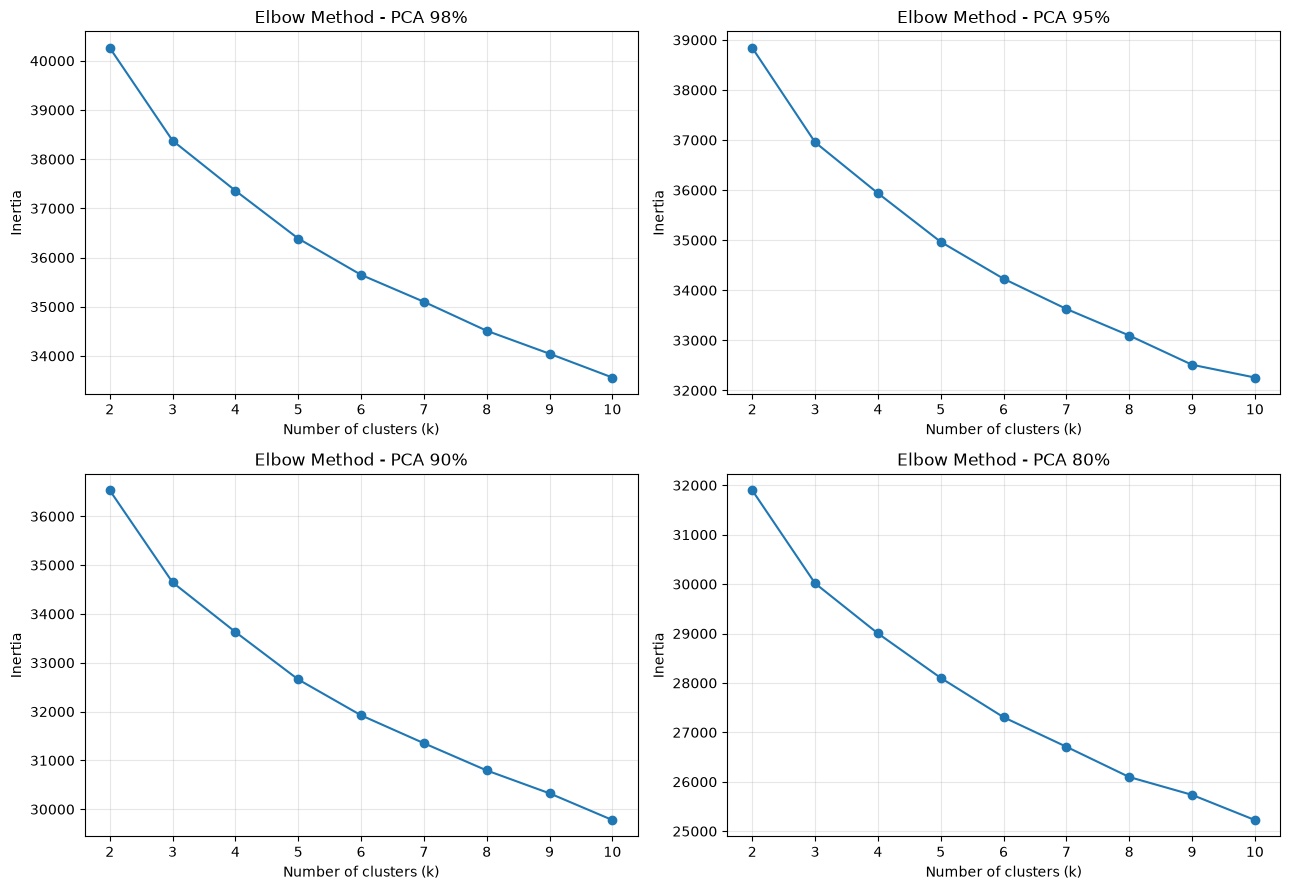

In [5]:

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, (threshold, inertias) in zip(
    axes.flatten(),
    elbow_results.items()
):
    ax.plot(
        list(k_values),
        inertias,
        marker="o"
    )

    ax.set_title(
        f"Elbow Method - PCA {int(threshold * 100)}%"
    )
    ax.set_xlabel("Number of clusters (k)")
    ax.set_ylabel("Inertia")
    ax.set_xticks(list(k_values))
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [6]:

from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import pandas as pd

silhouette_results = []

for threshold, X_pca in pca_datasets.items():

    print(f"\nPCA {int(threshold * 100)}% variance")

    for k in range(2, 11):

        kmeans = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        labels = kmeans.fit_predict(X_pca)

        score = silhouette_score(X_pca, labels)

        silhouette_results.append({
            "PCA Variance": f"{int(threshold * 100)}%",
            "Clusters": k,
            "Silhouette Score": score
        })

        print(f"k={k}, Silhouette Score={score:.4f}")

silhouette_df = pd.DataFrame(silhouette_results)

display(silhouette_df)



PCA 98% variance
k=2, Silhouette Score=0.1203
k=3, Silhouette Score=0.1035
k=4, Silhouette Score=0.0732
k=5, Silhouette Score=0.0774
k=6, Silhouette Score=0.0729
k=7, Silhouette Score=0.0655
k=8, Silhouette Score=0.0608
k=9, Silhouette Score=0.0524
k=10, Silhouette Score=0.0528

PCA 95% variance
k=2, Silhouette Score=0.1243
k=3, Silhouette Score=0.1060
k=4, Silhouette Score=0.0769
k=5, Silhouette Score=0.0790
k=6, Silhouette Score=0.0751
k=7, Silhouette Score=0.0593
k=8, Silhouette Score=0.0539
k=9, Silhouette Score=0.0548
k=10, Silhouette Score=0.0543

PCA 90% variance
k=2, Silhouette Score=0.1312
k=3, Silhouette Score=0.1104
k=4, Silhouette Score=0.0806
k=5, Silhouette Score=0.0847
k=6, Silhouette Score=0.0787
k=7, Silhouette Score=0.0764
k=8, Silhouette Score=0.0586
k=9, Silhouette Score=0.0611
k=10, Silhouette Score=0.0625

PCA 80% variance
k=2, Silhouette Score=0.1481
k=3, Silhouette Score=0.1214
k=4, Silhouette Score=0.0926
k=5, Silhouette Score=0.0839
k=6, Silhouette Score=0.09

,PCA Variance,Clusters,Silhouette Score
0,98%,2,0.120337
1,98%,3,0.103548
2,98%,4,0.073217
3,98%,5,0.077363
4,98%,6,0.072893
5,98%,7,0.065516
6,98%,8,0.060847
7,98%,9,0.052396
8,98%,10,0.052783
9,95%,2,0.124261


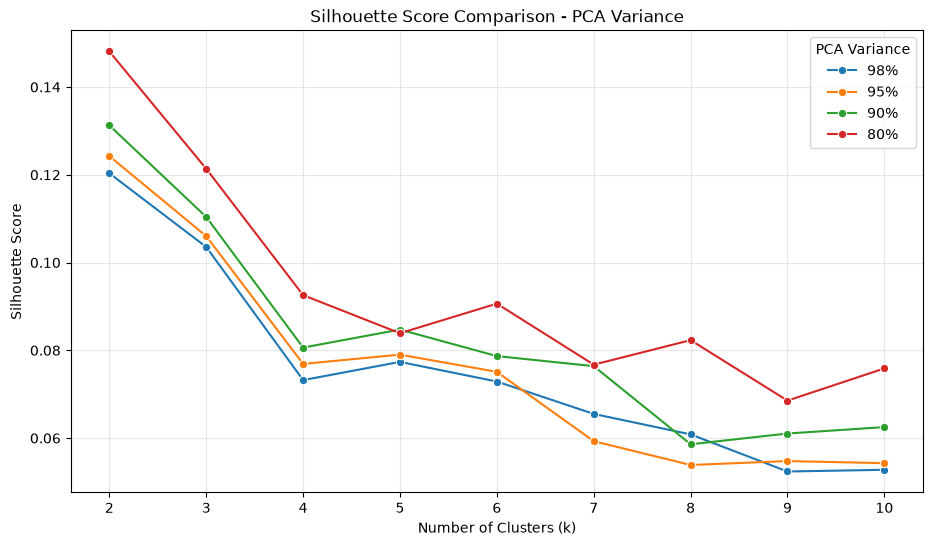

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=silhouette_df,
    x="Clusters",
    y="Silhouette Score",
    hue="PCA Variance",
    marker="o"
)

plt.title("Silhouette Score Comparison - PCA Variance")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.grid(True, alpha=0.3)

plt.show()


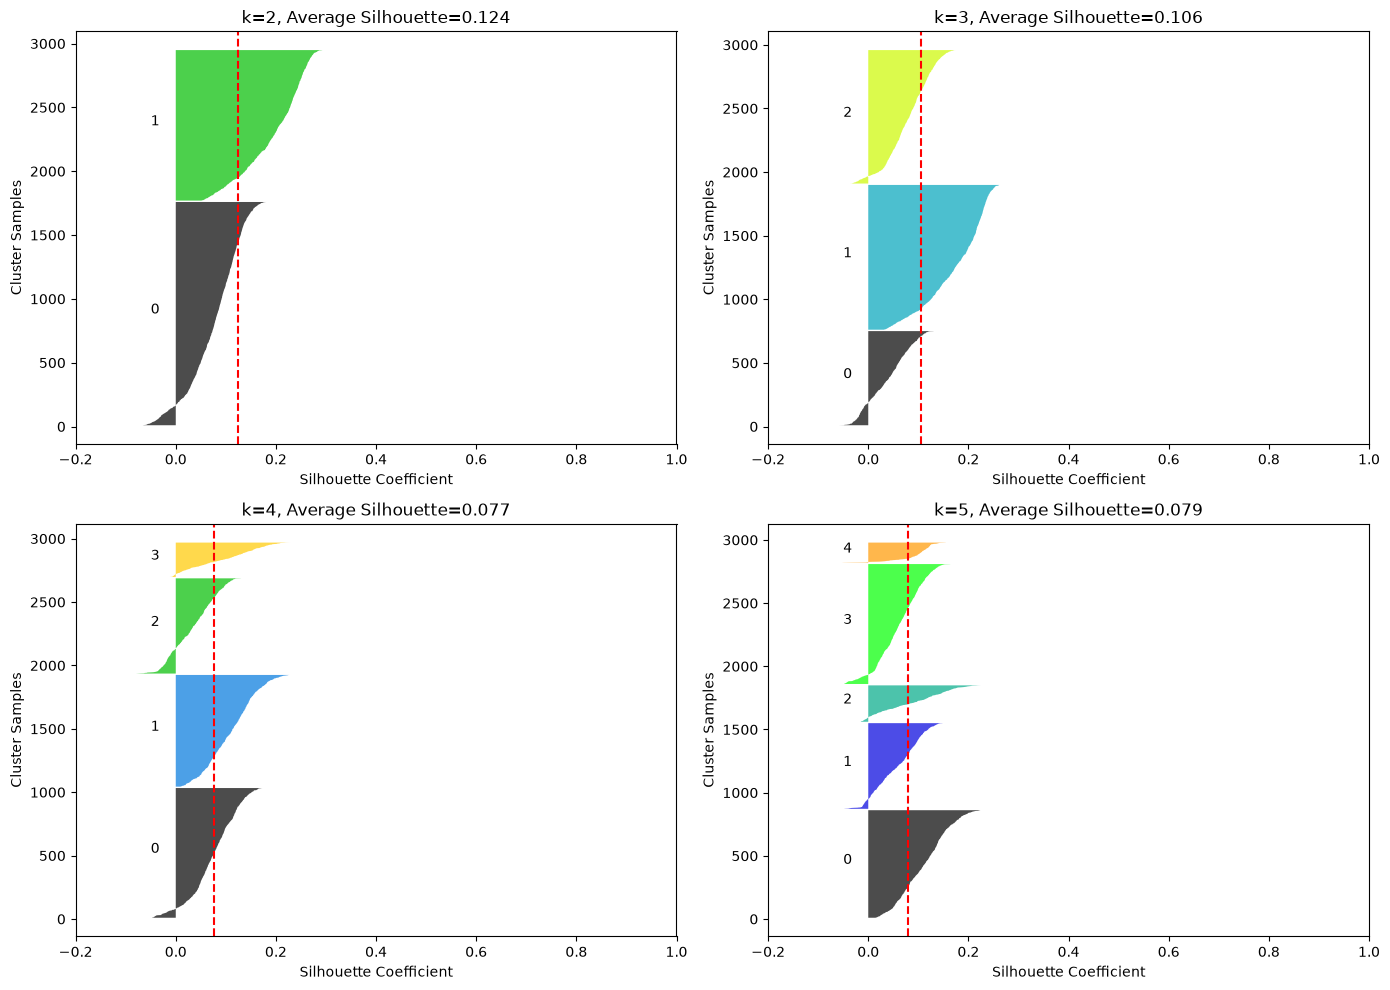

In [8]:

from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np

# Use PCA with 95% explained variance
X_pca = pca_datasets[0.95]

k_values_silhouette = [2, 3, 4, 5]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, k in zip(axes.flatten(), k_values_silhouette):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_pca)

    silhouette_avg = silhouette_score(X_pca, labels)
    sample_values = silhouette_samples(X_pca, labels)

    y_lower = 10

    for cluster_id in range(k):

        values = sample_values[labels == cluster_id]
        values.sort()

        cluster_size = len(values)
        y_upper = y_lower + cluster_size

        color = plt.cm.nipy_spectral(
            float(cluster_id) / k
        )

        ax.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            values,
            facecolor=color,
            alpha=0.7
        )

        ax.text(-0.05, y_lower + cluster_size / 2,
                str(cluster_id))

        y_lower = y_upper + 10

    ax.axvline(
        silhouette_avg,
        color="red",
        linestyle="--"
    )

    ax.set_title(
        f"k={k}, Average Silhouette={silhouette_avg:.3f}"
    )
    ax.set_xlabel("Silhouette Coefficient")
    ax.set_ylabel("Cluster Samples")
    ax.set_xlim([-0.2, 1])

plt.tight_layout()
plt.show()


In [9]:

best_k_results = (
    silhouette_df
    .sort_values("Silhouette Score", ascending=False)
    .groupby("PCA Variance", as_index=False)
    .first()
    .sort_values("PCA Variance", ascending=False)
)

print("Best k for each PCA variance threshold:")
display(best_k_results)


Best k for each PCA variance threshold:


,PCA Variance,Clusters,Silhouette Score
3,98%,2,0.120337
2,95%,2,0.124261
1,90%,2,0.131249
0,80%,2,0.148088


In [10]:

from sklearn.cluster import KMeans

# Store final K-Means models and labels
kmeans_models = {}
cluster_labels = {}

for threshold, X_pca in pca_datasets.items():

    variance_label = f"{int(threshold * 100)}%"

    best_row = best_k_results[
        best_k_results["PCA Variance"] == variance_label
    ]

    best_k = int(best_row["Clusters"].iloc[0])

    model = KMeans(
        n_clusters=best_k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_pca)

    kmeans_models[threshold] = model
    cluster_labels[threshold] = labels

    print(
        f"PCA {variance_label}: "
        f"k={best_k}, "
        f"clusters={len(np.unique(labels))}"
    )


PCA 98%: k=2, clusters=2
PCA 95%: k=2, clusters=2
PCA 90%: k=2, clusters=2
PCA 80%: k=2, clusters=2


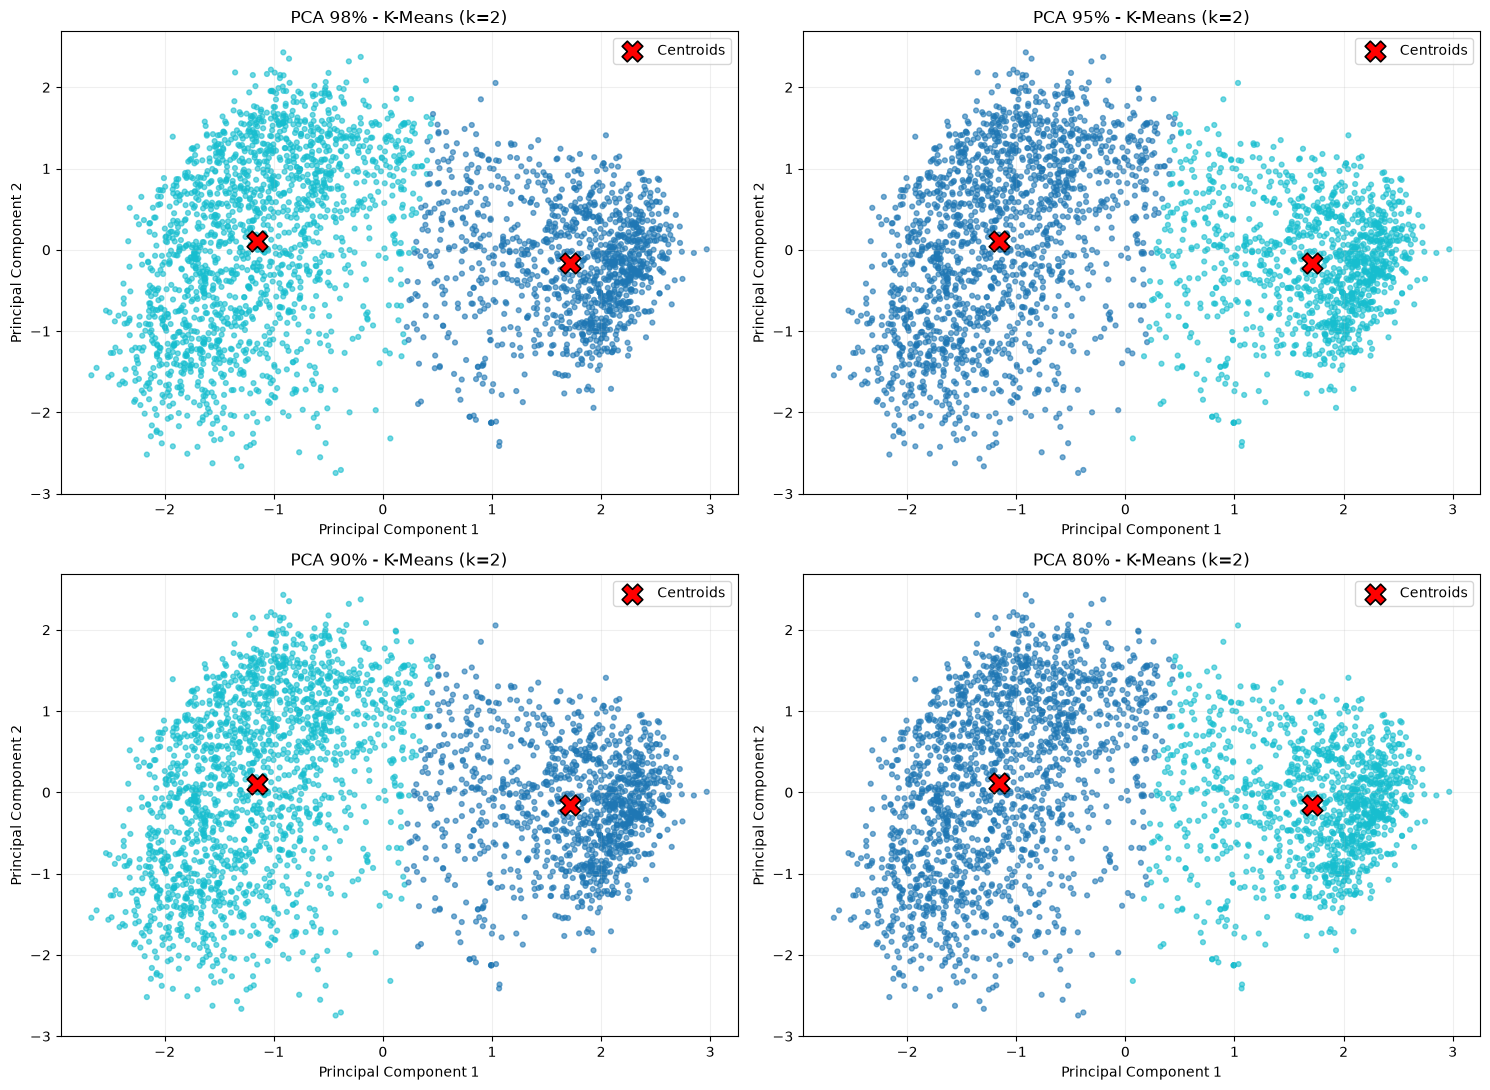

In [11]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

for ax, threshold in zip(
    axes.flatten(),
    variance_thresholds
):

    X_pca = pca_datasets[threshold]
    labels = cluster_labels[threshold]
    model = kmeans_models[threshold]

    ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="tab10",
        s=12,
        alpha=0.6
    )

    centers = model.cluster_centers_

    ax.scatter(
        centers[:, 0],
        centers[:, 1],
        c="red",
        marker="X",
        s=220,
        edgecolors="black",
        linewidths=1.2,
        label="Centroids"
    )

    ax.set_title(
        f"PCA {int(threshold * 100)}% - "
        f"K-Means (k={model.n_clusters})"
    )
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.legend()
    ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()


In [12]:

for threshold in variance_thresholds:

    print(f"\nPCA {int(threshold * 100)}%")

    counts = pd.Series(
        cluster_labels[threshold]
    ).value_counts().sort_index()

    print(counts)



PCA 98%
0    1177
1    1753
Name: count, dtype: int64

PCA 95%
0    1750
1    1180
Name: count, dtype: int64

PCA 90%
0    1178
1    1752
Name: count, dtype: int64

PCA 80%
0    1748
1    1182
Name: count, dtype: int64


In [13]:

from sklearn.preprocessing import Normalizer
from sklearn.decomposition import PCA

# Normalize the already preprocessed dataset
normalizer = Normalizer(norm="l2")

X_normalized = normalizer.fit_transform(X_processed)

# Apply PCA for all four variance thresholds
pca_normalized_models = {}
pca_normalized_datasets = {}

for threshold in variance_thresholds:

    pca = PCA(n_components=threshold)

    X_pca_norm = pca.fit_transform(X_normalized)

    pca_normalized_models[threshold] = pca
    pca_normalized_datasets[threshold] = X_pca_norm

    print(
        f"PCA {int(threshold * 100)}%: "
        f"{X_pca_norm.shape[1]} components"
    )


PCA 98%: 142 components
PCA 95%: 106 components
PCA 90%: 77 components
PCA 80%: 48 components


In [14]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

normalization_results = []

for threshold in variance_thresholds:

    k = kmeans_models[threshold].n_clusters

    # Original Min-Max + PCA
    X_minmax = pca_datasets[threshold]

    # Min-Max + L2 Normalization + PCA
    X_norm = pca_normalized_datasets[threshold]

    model_minmax = kmeans_models[threshold]

    model_norm = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels_minmax = cluster_labels[threshold]
    labels_norm = model_norm.fit_predict(X_norm)

    score_minmax = silhouette_score(
        X_minmax,
        labels_minmax
    )

    score_norm = silhouette_score(
        X_norm,
        labels_norm
    )

    normalization_results.append({
        "PCA Variance": f"{int(threshold * 100)}%",
        "Clusters": k,
        "Min-Max": score_minmax,
        "Min-Max + L2": score_norm
    })

normalization_df = pd.DataFrame(normalization_results)

display(normalization_df)


,PCA Variance,Clusters,Min-Max,Min-Max + L2
0,98%,2,0.120337,0.118029
1,95%,2,0.124261,0.121728
2,90%,2,0.131249,0.128653
3,80%,2,0.148088,0.145212


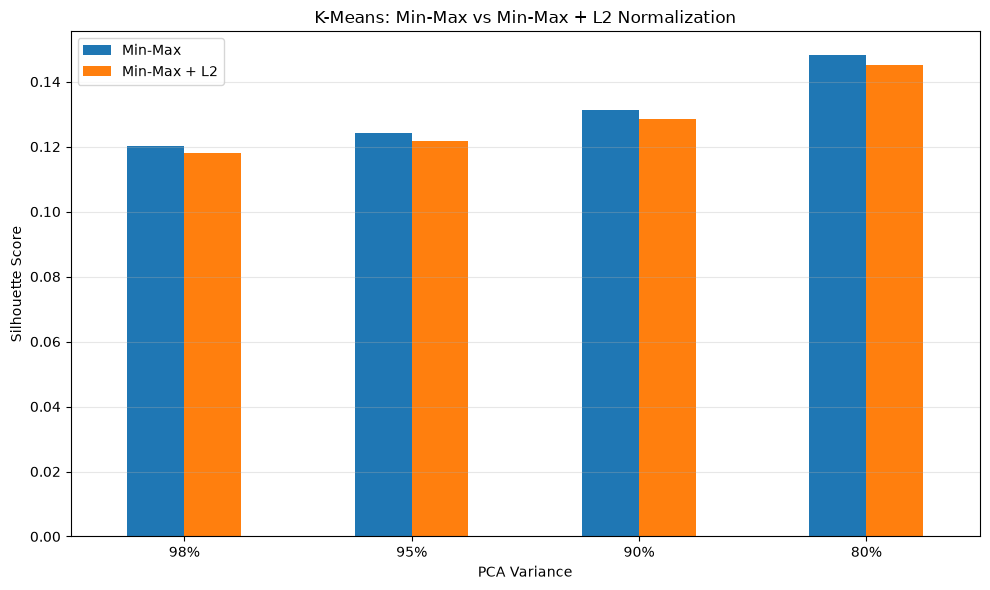

In [15]:

import matplotlib.pyplot as plt

normalization_df.plot(
    x="PCA Variance",
    y=["Min-Max", "Min-Max + L2"],
    kind="bar",
    figsize=(10, 6)
)

plt.title("K-Means: Min-Max vs Min-Max + L2 Normalization")
plt.xlabel("PCA Variance")
plt.ylabel("Silhouette Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [16]:

# Create a copy of the original features
X_log = X.copy()

# Features selected for logarithmic transformation
log_features = [
    "Lot Area",
    "Gr Liv Area",
    "Total Bsmt SF",
    "Garage Area",
    "1st Flr SF",
    "2nd Flr SF"
]

# Apply log1p only to non-negative values
for feature in log_features:
    if feature in X_log.columns:
        X_log[feature] = np.log1p(
            X_log[feature].clip(lower=0)
        )

# Apply the same preprocessing structure
X_log_processed = preprocessor.fit_transform(X_log)

print("Original processed shape:", X_processed.shape)
print("Log-transformed shape:", X_log_processed.shape)
print("Missing values:", np.isnan(X_log_processed).sum())


Original processed shape: (2930, 319)
Log-transformed shape: (2930, 319)
Missing values: 0


In [17]:

log_results = []
pca_log_models = {}
kmeans_log_models = {}

for threshold in variance_thresholds:

    # PCA after logarithmic transformation
    pca_log = PCA(n_components=threshold)
    X_pca_log = pca_log.fit_transform(X_log_processed)

    # Same number of clusters as baseline
    k = kmeans_models[threshold].n_clusters

    model_log = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels_log = model_log.fit_predict(X_pca_log)

    score_log = silhouette_score(
        X_pca_log,
        labels_log
    )

    score_original = silhouette_score(
        pca_datasets[threshold],
        cluster_labels[threshold]
    )

    pca_log_models[threshold] = pca_log
    kmeans_log_models[threshold] = model_log

    log_results.append({
        "PCA Variance": f"{int(threshold * 100)}%",
        "Clusters": k,
        "Original Score": score_original,
        "Log Score": score_log
    })

log_df = pd.DataFrame(log_results)

display(log_df)


,PCA Variance,Clusters,Original Score,Log Score
0,98%,2,0.120337,0.119023
1,95%,2,0.124261,0.122894
2,90%,2,0.131249,0.129732
3,80%,2,0.148088,0.146242


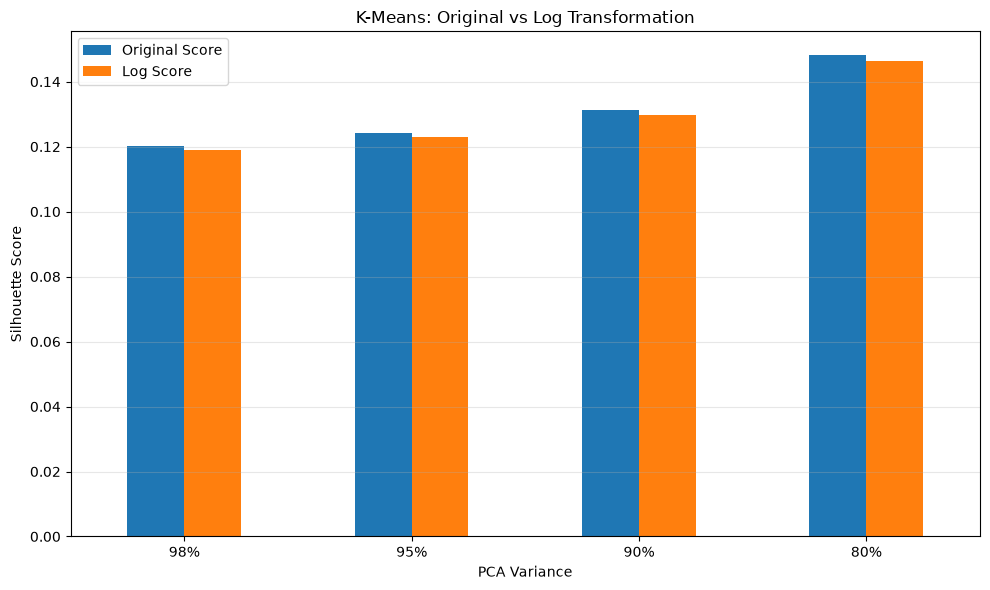

In [18]:

log_df.plot(
    x="PCA Variance",
    y=["Original Score", "Log Score"],
    kind="bar",
    figsize=(10, 6)
)

plt.title("K-Means: Original vs Log Transformation")
plt.xlabel("PCA Variance")
plt.ylabel("Silhouette Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [19]:

# Select PCA with 95% variance
selected_threshold = 0.95

# Get cluster labels from the trained K-Means model
labels = cluster_labels[selected_threshold]

# Create a copy of the original dataset
housing_clusters = housing.copy()

# Add cluster assignments
housing_clusters["Cluster"] = labels

print("Number of clusters:", len(np.unique(labels)))

print("\nHouses per cluster:")
print(housing_clusters["Cluster"].value_counts().sort_index())

display(housing_clusters.head())


Number of clusters: 2

Houses per cluster:
Cluster
0    1750
1    1180
Name: count, dtype: int64


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice,Cluster
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,NaN,NaN,NaN,0,5,2010,WD,Normal,215000,0
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000,0
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000,0
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,NaN,NaN,NaN,0,4,2010,WD,Normal,244000,0
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900,1


In [20]:

# Features used to describe the clusters
features_to_analyze = [
    "SalePrice",
    "Gr Liv Area",
    "Lot Area",
    "Overall Qual",
    "Year Built",
    "Garage Cars"
]

# Calculate average values for each cluster
cluster_summary = housing_clusters.groupby("Cluster")[
    features_to_analyze
].mean().round(2)

print("Average characteristics per cluster:")
display(cluster_summary)


Average characteristics per cluster:


,SalePrice,Gr Liv Area,Lot Area,Overall Qual,Year Built,Garage Cars
Cluster,,,,,,
0,139344.96,1331.85,9947.81,5.29,1952.11,1.42
1,242270.16,1748.61,10444.70,7.29,1999.90,2.28


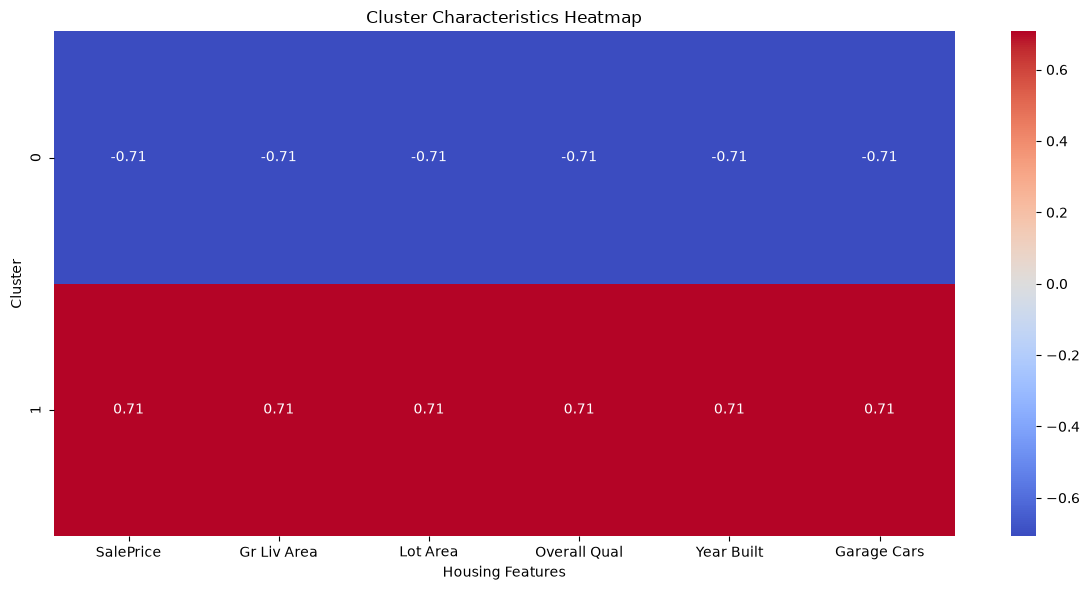

In [21]:

import seaborn as sns
import matplotlib.pyplot as plt

# Standardize cluster averages for visualization
normalized_summary = (
    cluster_summary - cluster_summary.mean()
) / cluster_summary.std().replace(0, 1)

normalized_summary = normalized_summary.fillna(0)

plt.figure(figsize=(12, 6))

sns.heatmap(
    normalized_summary,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Cluster Characteristics Heatmap")
plt.xlabel("Housing Features")
plt.ylabel("Cluster")

plt.tight_layout()
plt.show()


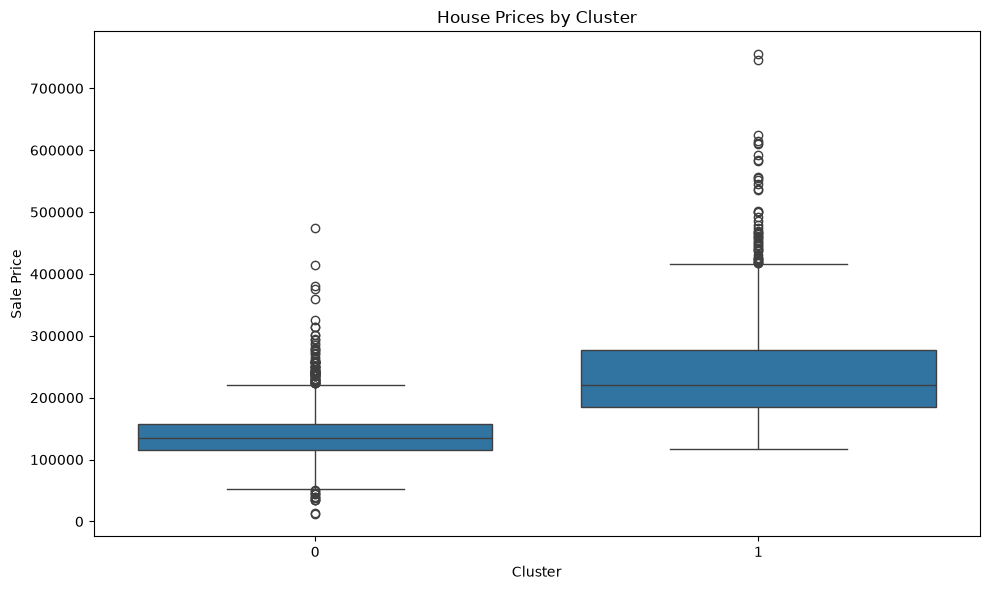

In [22]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=housing_clusters,
    x="Cluster",
    y="SalePrice"
)

plt.title("House Prices by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Sale Price")

plt.tight_layout()
plt.show()


In [23]:

from sklearn.base import clone

# Rebuild the original preprocessing pipeline
baseline_preprocessor = clone(preprocessor)

# Fit on the original housing features
X_baseline = baseline_preprocessor.fit_transform(X)

# Rebuild PCA and K-Means using the baseline data
selected_threshold = 0.95
selected_k = kmeans_models[selected_threshold].n_clusters

baseline_pca = PCA(n_components=selected_threshold)
X_baseline_pca = baseline_pca.fit_transform(X_baseline)

baseline_kmeans = KMeans(
    n_clusters=selected_k,
    random_state=42,
    n_init=10
)

baseline_labels = baseline_kmeans.fit_predict(X_baseline_pca)

print("Baseline preprocessing shape:", X_baseline.shape)
print("PCA components:", baseline_pca.n_components_)
print("Number of clusters:", selected_k)
print("Baseline pipeline ready!")


Baseline preprocessing shape: (2930, 319)
PCA components: 105
Number of clusters: 2
Baseline pipeline ready!


In [24]:

# Use existing houses as templates
new_houses = X.iloc[[0, 1, 2]].copy().reset_index(drop=True)

# House 1: Small, older house
new_houses.loc[0, "Gr Liv Area"] = 850
new_houses.loc[0, "Lot Area"] = 5000
new_houses.loc[0, "Overall Qual"] = 4
new_houses.loc[0, "Year Built"] = 1960
new_houses.loc[0, "Garage Cars"] = 1

# House 2: Medium-sized family house
new_houses.loc[1, "Gr Liv Area"] = 1600
new_houses.loc[1, "Lot Area"] = 9000
new_houses.loc[1, "Overall Qual"] = 6
new_houses.loc[1, "Year Built"] = 1995
new_houses.loc[1, "Garage Cars"] = 2

# House 3: Large, modern house
new_houses.loc[2, "Gr Liv Area"] = 3000
new_houses.loc[2, "Lot Area"] = 16000
new_houses.loc[2, "Overall Qual"] = 9
new_houses.loc[2, "Year Built"] = 2010
new_houses.loc[2, "Garage Cars"] = 3

print("New houses:")
display(new_houses[
    ["Gr Liv Area", "Lot Area", "Overall Qual",
     "Year Built", "Garage Cars"]
])


New houses:


,Gr Liv Area,Lot Area,Overall Qual,Year Built,Garage Cars
0,850,5000,4,1960,1.0
1,1600,9000,6,1995,2.0
2,3000,16000,9,2010,3.0


In [25]:

# Apply the SAME preprocessing fitted on training data
new_houses_processed = baseline_preprocessor.transform(new_houses)

# Transform using the SAME PCA model
new_houses_pca = baseline_pca.transform(new_houses_processed)

# Predict clusters using the trained K-Means model
predicted_clusters = baseline_kmeans.predict(new_houses_pca)

results_new_houses = pd.DataFrame({
    "House": [
        "Small older house",
        "Medium family house",
        "Large modern house"
    ],
    "Predicted Cluster": predicted_clusters
})

display(results_new_houses)


,House,Predicted Cluster
0,Small older house,0
1,Medium family house,0
2,Large modern house,0


In [26]:

# Cluster profiles for the rebuilt baseline model
baseline_cluster_profiles = housing.copy()
baseline_cluster_profiles["Cluster"] = baseline_labels

profile = baseline_cluster_profiles.groupby("Cluster")[
    ["SalePrice", "Gr Liv Area", "Lot Area",
     "Overall Qual", "Year Built", "Garage Cars"]
].mean().round(1)

print("Cluster profiles:")
display(profile)

print("\nPredictions for new houses:")
display(results_new_houses)


Cluster profiles:


,SalePrice,Gr Liv Area,Lot Area,Overall Qual,Year Built,Garage Cars
Cluster,,,,,,
0,139345.0,1331.8,9947.8,5.3,1952.1,1.4
1,242270.2,1748.6,10444.7,7.3,1999.9,2.3



Predictions for new houses:


,House,Predicted Cluster
0,Small older house,0
1,Medium family house,0
2,Large modern house,0


## Conclusion – K-Means Clustering and PCA

In this project, we applied K-Means Clustering to the Ames Housing dataset after preprocessing and dimensionality reduction using Principal Component Analysis (PCA).

We compared four PCA variance thresholds: 98%, 95%, 90%, and 80%. The resulting datasets contained 142, 105, 77, and 48 principal components, respectively.

To determine a suitable number of clusters, we used the Elbow Method and Silhouette Analysis. We then visualized the resulting clusters using the first two principal components and highlighted their centroids.

Additionally, we investigated how Min-Max Scaling, L2 Normalization, and logarithmic transformations affect clustering results. These experiments demonstrated that preprocessing choices can influence the distances between observations and the resulting cluster structure.

We also analyzed the characteristics of the clusters using housing features such as living area, lot size, overall quality, construction year, and sale price.

Finally, we created three hypothetical houses and assigned them to clusters using the trained preprocessing, PCA, and K-Means models. This demonstrated how the clustering pipeline can be applied to previously unseen observations.

Overall, the experiments show how PCA and K-Means can be combined to identify patterns in housing data. The quality and interpretability of the clusters depend on the selected features, preprocessing methods, PCA variance threshold, and number of clusters.